In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
DATA = "../data/"
rec = 18              # recording number. 18 to 29 are all at the Frankenburg intersection

tracks = pd.read_csv(f"{DATA}{rec}_tracks.csv")
meta = pd.read_csv(f"{DATA}{rec}_tracksMeta.csv")
rec_meta = pd.read_csv(f"{DATA}{rec}_recordingMeta.csv")

print("tracks:", tracks.shape)
print("meta:", meta.shape)

tracks: (625989, 17)
meta: (427, 8)


In [4]:
tracks.head()

,recordingId,trackId,frame,trackLifetime,xCenter,yCenter,heading,width,length,xVelocity,yVelocity,xAcceleration,yAcceleration,lonVelocity,latVelocity,lonAcceleration,latAcceleration
0,18,0,0,0,84.30107,-22.02852,194.94744,1.85331,4.41079,-7.91662,-1.91685,-0.07138,-0.14320,8.14317,0.18997,0.10590,-0.11994
1,18,0,1,1,83.98532,-22.10562,194.94288,1.85331,4.41079,-7.92878,-1.92552,-0.05625,-0.14088,8.15716,0.18408,0.09067,-0.12162
2,18,0,2,2,83.66711,-22.18349,194.92958,1.85331,4.41079,-7.93992,-1.93380,-0.03202,-0.13578,8.17010,0.17706,0.06592,-0.12294
3,18,0,3,3,83.34667,-22.26174,194.91645,1.85331,4.41079,-7.94897,-1.94156,0.00054,-0.12818,8.18088,0.17001,0.03248,-0.12400
4,18,0,4,4,83.02679,-22.33976,194.91210,1.85331,4.41079,-7.95595,-1.94891,0.04048,-0.11831,8.18953,0.16408,-0.00867,-0.12474


class
car           181
pedestrian    154
bicycle        92
Name: count, dtype: int64


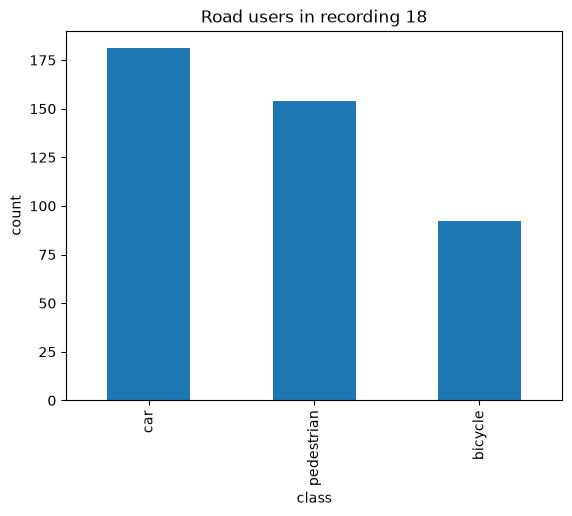

In [5]:
counts = meta["class"].value_counts()
print(counts)

counts.plot(kind="bar")
plt.title(f"Road users in recording {rec}")
plt.ylabel("count")
plt.show()

In [6]:
print("frame rate:", rec_meta["frameRate"][0], "frames per second")
print("duration:", round(rec_meta["duration"][0] / 60, 1), "minutes")
print("metres per image pixel:", rec_meta["orthoPxToMeter"][0])

frame rate: 25.0 frames per second
duration: 18.7 minutes
metres per image pixel: 0.008146360917245


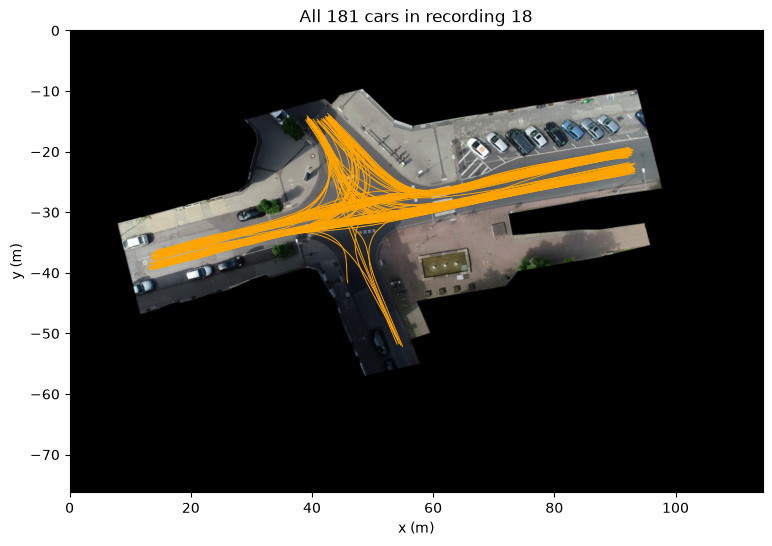

In [7]:
image = plt.imread(f"{DATA}{rec}_background.png")

# The background image is 12 times smaller than the original drone image (this is how the inD tools do it),
# so one pixel of this image = orthoPxToMeter * 12 metres.
metres_per_pixel = rec_meta["orthoPxToMeter"][0] * 12
height, width = image.shape[:2]

# extent = [left, right, bottom, top] in metres.
# The y axis of inD points up, while image rows go down, so the image goes from 0 to minus its height.
extent = [0, width * metres_per_pixel, -height * metres_per_pixel, 0]

car_ids = meta[meta["class"] == "car"]["trackId"]

plt.figure(figsize=(9, 6))
plt.imshow(image, extent=extent)
for car_id in car_ids:
    car = tracks[tracks["trackId"] == car_id]
    plt.plot(car["xCenter"], car["yCenter"], color="orange", linewidth=0.7)
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title(f"All {len(car_ids)} cars in recording {rec}")
plt.savefig("../figures/01_tracks_on_map.png", dpi=150, bbox_inches="tight")
plt.show()

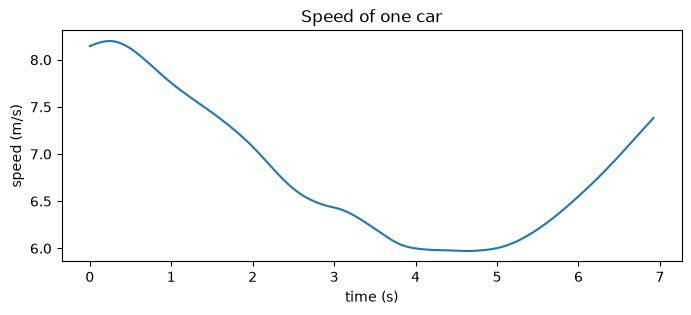

number of frames for this car: 174


In [8]:
car = tracks[tracks["trackId"] == car_ids.iloc[0]]

time = car["frame"] / 25                                    # frame number -> seconds
speed = np.sqrt(car["xVelocity"]**2 + car["yVelocity"]**2)  # length of the velocity vector

plt.figure(figsize=(8, 3))
plt.plot(time, speed)
plt.xlabel("time (s)")
plt.ylabel("speed (m/s)")
plt.title("Speed of one car")
plt.show()

print("number of frames for this car:", len(car))